✅ Loaded model from: best_model.pt
Model classes: {0: 'echinus', 1: 'holothurian', 2: 'scallop', 3: 'starfish'}

image 1/1 y:\A.Poojitha\projects\growth project\detection\URPC2020-2\valid\images\000955_jpg.rf.70c3cc20cd4a75f8572e3ef1ab9d5012.jpg: 512x512 2 scallops, 562.4ms
Speed: 4.8ms preprocess, 562.4ms inference, 1.6ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs\detect\predict11

📸 Annotated image saved to: runs\detect\predict11
Full path: runs\detect\predict11\000955_jpg.rf.70c3cc20cd4a75f8572e3ef1ab9d5012.jpg


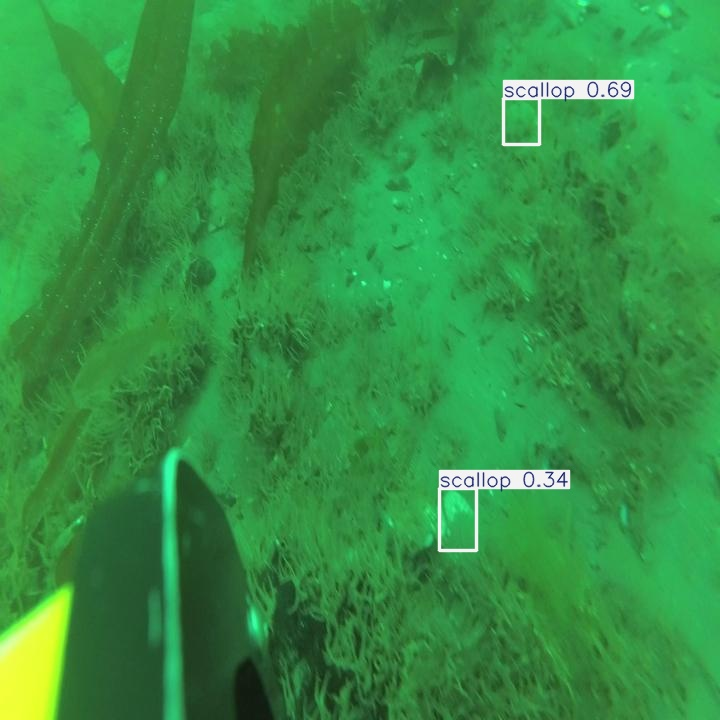


DETECTION RESULTS:
 1. scallop      | conf=0.6862 | box=(503.4, 98.9, 539.3, 144.4)
 2. scallop      | conf=0.3360 | box=(439.1, 488.6, 476.3, 550.0)

AS DATAFRAME:
 No.   Class Confidence           BBox [x1,y1,x2,y2]
   1 scallop     0.6862  [503.4, 98.9, 539.3, 144.4]
   2 scallop     0.3360 [439.1, 488.6, 476.3, 550.0]

🎉 Inference completed successfully!


In [1]:
# Full inference code for YOLO11m + CSEA (corrected)
# ------------------------------------------------
from ultralytics import YOLO
import torch
import pandas as pd
from IPython.display import Image as IPyImage, display
import os
from pathlib import Path

# 1. Path to your trained best model
best_model_path = "best_model.pt"

# 2. Load model
model = YOLO(best_model_path)
print(f"✅ Loaded model from: {best_model_path}")
print(f"Model classes: {model.names}")

# 3. Image path (change to your raw image)
image_path = r"URPC2020-2\valid\images\000955_jpg.rf.70c3cc20cd4a75f8572e3ef1ab9d5012.jpg"

# 4. Run inference (save annotated image)
results = model(image_path, save=True, conf=0.25)

# 5. Display saved annotated image - FIXED using os.path.join
save_dir = results[0].save_dir  # this is a string
img_filename = os.path.basename(results[0].path)  # get filename
saved_img_path = os.path.join(save_dir, img_filename)  # correct join

print(f"\n📸 Annotated image saved to: {save_dir}")
print(f"Full path: {saved_img_path}")
display(IPyImage(filename=saved_img_path))

# 6. Print detection details with proper tensor conversion
print("\n" + "="*60)
print("DETECTION RESULTS:")
print("="*60)

boxes = results[0].boxes
detections = []

for i, box in enumerate(boxes, 1):
    cls_id = int(box.cls.item())
    conf = box.conf.item()
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    
    class_name = model.names[cls_id]
    detections.append({
        'No.': i,
        'Class': class_name,
        'Confidence': f"{conf:.4f}",
        'BBox [x1,y1,x2,y2]': f"[{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]"
    })
    
    print(f"{i:2d}. {class_name:12s} | conf={conf:.4f} | box=({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})")

# 7. DataFrame for analysis
df = pd.DataFrame(detections)
print("\n" + "="*60)
print("AS DATAFRAME:")
print(df.to_string(index=False))

# 8. (Optional) Run on entire test folder
# Uncomment if needed:
# test_folder = "/kaggle/working/URPC2020-2/test/images/"
# results_all = model.predict(source=test_folder, save=True, conf=0.25, save_txt=True)
# print(f"\n✅ Predictions saved for all images in {test_folder}")

print("\n🎉 Inference completed successfully!")

✅ Loaded model from: best_model.pt

image 1/1 y:\A.Poojitha\projects\growth project\detection\URPC2020-2\test\images\000012_jpg.rf.2cff4e52a9fbcb40ba943d7cf29a52de.jpg: 512x512 2 holothurians, 528.3ms
Speed: 6.4ms preprocess, 528.3ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs\detect\predict12

📸 Annotated image saved to: runs\detect\predict12\000012_jpg.rf.2cff4e52a9fbcb40ba943d7cf29a52de.jpg


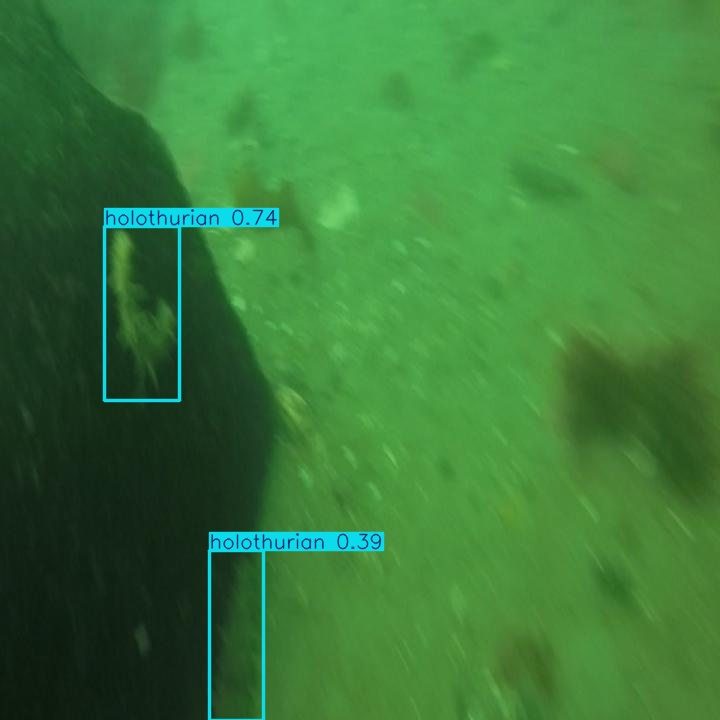


DETECTION RESULTS:
 1. holothurian  | conf=0.7399 | box=(104.7, 226.5, 179.6, 400.6)
 2. holothurian  | conf=0.3888 | box=(209.0, 551.0, 263.8, 720.0)


In [2]:
from ultralytics import YOLO
import os
from IPython.display import Image as IPyImage, display
import pandas as pd

# 1. Path to your trained model
best_model_path = "best_model.pt"   # ensure this file exists in working dir
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Model not found: {best_model_path}")

# 2. Load model
model = YOLO(best_model_path)
print(f"✅ Loaded model from: {best_model_path}")

# 3. Image path (use forward slashes)
image_path = r"URPC2020-2\test\images\000012_jpg.rf.2cff4e52a9fbcb40ba943d7cf29a52de.jpg"


# Check file existence
if not os.path.exists(image_path):
    print(f"❌ Image not found: {image_path}")
    # Fallback: try to find any image in the test folder
    test_folder = "URPC2020-2/test/images"
    if os.path.exists(test_folder):
        images = [f for f in os.listdir(test_folder) if f.endswith(('.jpg', '.png'))]
        if images:
            image_path = os.path.join(test_folder, images[0])
            print(f"Using alternative image: {image_path}")
        else:
            raise FileNotFoundError("No test images found")
    else:
        raise FileNotFoundError(f"Test folder not found: {test_folder}")

# 4. Run inference
results = model(image_path, save=True, conf=0.25)

# 5. Display annotated image
save_dir = results[0].save_dir
img_filename = os.path.basename(results[0].path)
saved_img_path = os.path.join(save_dir, img_filename)
print(f"\n📸 Annotated image saved to: {saved_img_path}")
display(IPyImage(filename=saved_img_path))

# 6. Print detections
print("\n" + "="*60)
print("DETECTION RESULTS:")
boxes = results[0].boxes
if boxes is not None:
    for i, box in enumerate(boxes, 1):
        cls_id = int(box.cls.item())
        conf = box.conf.item()
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        class_name = model.names[cls_id]
        print(f"{i:2d}. {class_name:12s} | conf={conf:.4f} | box=({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})")
else:
    print("No objects detected.")

✅ Loaded model from: best_model.pt

image 1/1 y:\A.Poojitha\projects\growth project\detection\URPC2020-2\test\images\000100_jpg.rf.1247e1f87b7f8b7718a449215a3a2567.jpg: 512x512 5 starfishs, 566.6ms
Speed: 4.3ms preprocess, 566.6ms inference, 2.1ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs\detect\predict13

📸 Annotated image saved to: runs\detect\predict13\000100_jpg.rf.1247e1f87b7f8b7718a449215a3a2567.jpg


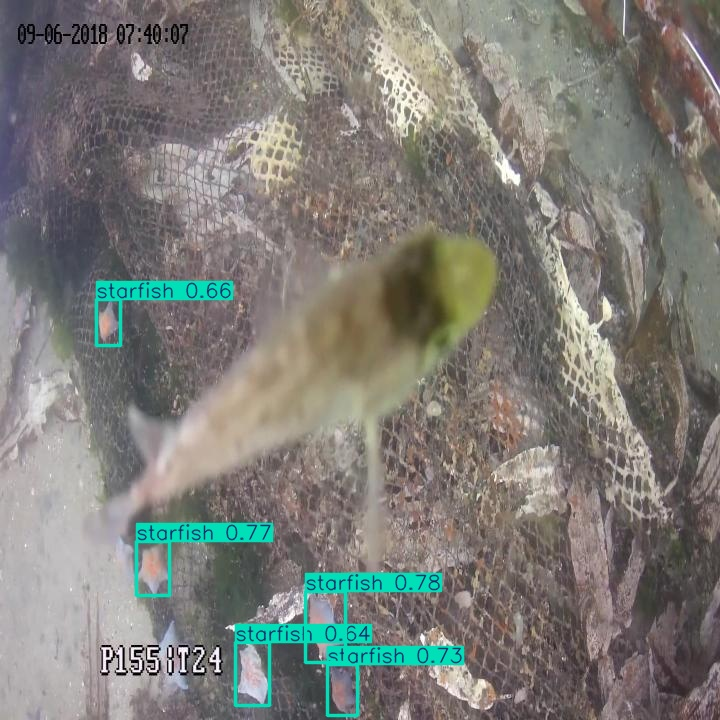


DETECTION RESULTS:
 1. starfish     | conf=0.7811 | box=(305.7, 591.7, 345.6, 662.5)
 2. starfish     | conf=0.7697 | box=(136.8, 541.7, 169.7, 595.7)
 3. starfish     | conf=0.7280 | box=(327.8, 664.9, 357.1, 715.2)
 4. starfish     | conf=0.6565 | box=(96.8, 299.7, 120.1, 345.9)
 5. starfish     | conf=0.6384 | box=(235.6, 642.6, 269.5, 705.1)


In [3]:
from ultralytics import YOLO
import os
from IPython.display import Image as IPyImage, display
import pandas as pd

# 1. Path to your trained model
best_model_path = "best_model.pt"   # ensure this file exists in working dir
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Model not found: {best_model_path}")

# 2. Load model
model = YOLO(best_model_path)
print(f"✅ Loaded model from: {best_model_path}")

# 3. Image path (use forward slashes)
image_path = r"URPC2020-2\test\images\000100_jpg.rf.1247e1f87b7f8b7718a449215a3a2567.jpg"


# Check file existence
if not os.path.exists(image_path):
    print(f"❌ Image not found: {image_path}")
    # Fallback: try to find any image in the test folder
    test_folder = "URPC2020-2/test/images"
    if os.path.exists(test_folder):
        images = [f for f in os.listdir(test_folder) if f.endswith(('.jpg', '.png'))]
        if images:
            image_path = os.path.join(test_folder, images[0])
            print(f"Using alternative image: {image_path}")
        else:
            raise FileNotFoundError("No test images found")
    else:
        raise FileNotFoundError(f"Test folder not found: {test_folder}")

# 4. Run inference
results = model(image_path, save=True, conf=0.25)

# 5. Display annotated image
save_dir = results[0].save_dir
img_filename = os.path.basename(results[0].path)
saved_img_path = os.path.join(save_dir, img_filename)
print(f"\n📸 Annotated image saved to: {saved_img_path}")
display(IPyImage(filename=saved_img_path))

# 6. Print detections
print("\n" + "="*60)
print("DETECTION RESULTS:")
boxes = results[0].boxes
if boxes is not None:
    for i, box in enumerate(boxes, 1):
        cls_id = int(box.cls.item())
        conf = box.conf.item()
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        class_name = model.names[cls_id]
        print(f"{i:2d}. {class_name:12s} | conf={conf:.4f} | box=({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})")
else:
    print("No objects detected.")

✅ Loaded model from: best_model.pt

image 1/1 y:\A.Poojitha\projects\growth project\detection\URPC2020-2\test\images\000213_jpg.rf.a0c0402c65d0e2e9895a63bfcf974844.jpg: 512x512 3 echinuss, 1 scallop, 1 starfish, 456.9ms
Speed: 2.9ms preprocess, 456.9ms inference, 1.0ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs\detect\predict14

📸 Annotated image saved to: runs\detect\predict14\000213_jpg.rf.a0c0402c65d0e2e9895a63bfcf974844.jpg


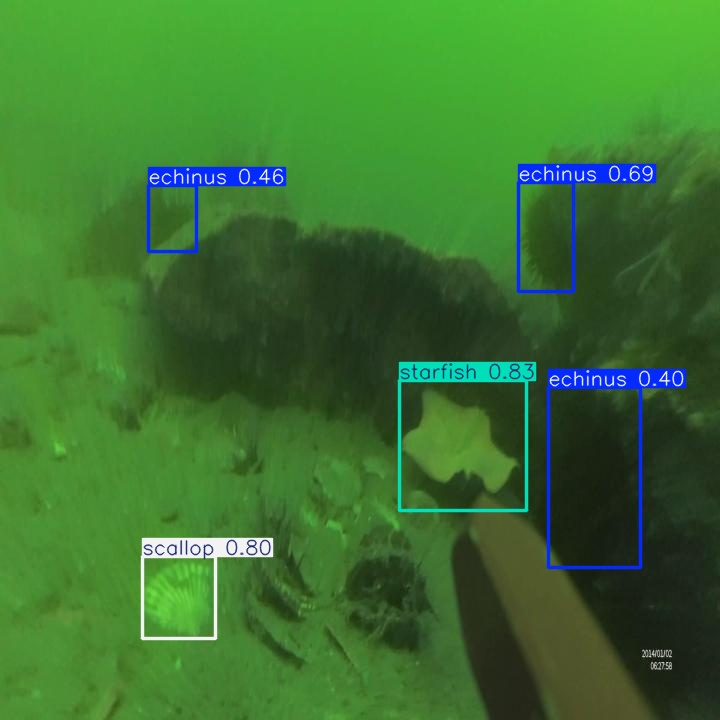


DETECTION RESULTS:
 1. starfish     | conf=0.8258 | box=(399.4, 380.4, 526.9, 510.0)
 2. scallop      | conf=0.8006 | box=(142.3, 556.2, 215.0, 639.0)
 3. echinus      | conf=0.6857 | box=(518.9, 182.2, 573.0, 291.0)
 4. echinus      | conf=0.4597 | box=(148.8, 185.7, 196.8, 251.9)
 5. echinus      | conf=0.3952 | box=(548.2, 387.1, 640.4, 567.4)


In [4]:
from ultralytics import YOLO
import os
from IPython.display import Image as IPyImage, display
import pandas as pd

# 1. Path to your trained model
best_model_path = "best_model.pt"   # ensure this file exists in working dir
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Model not found: {best_model_path}")

# 2. Load model
model = YOLO(best_model_path)
print(f"✅ Loaded model from: {best_model_path}")

# 3. Image path (use forward slashes)
image_path = r"URPC2020-2\test\images\000213_jpg.rf.a0c0402c65d0e2e9895a63bfcf974844.jpg"


# Check file existence
if not os.path.exists(image_path):
    print(f"❌ Image not found: {image_path}")
    # Fallback: try to find any image in the test folder
    test_folder = "URPC2020-2/test/images"
    if os.path.exists(test_folder):
        images = [f for f in os.listdir(test_folder) if f.endswith(('.jpg', '.png'))]
        if images:
            image_path = os.path.join(test_folder, images[0])
            print(f"Using alternative image: {image_path}")
        else:
            raise FileNotFoundError("No test images found")
    else:
        raise FileNotFoundError(f"Test folder not found: {test_folder}")

# 4. Run inference
results = model(image_path, save=True, conf=0.25)

# 5. Display annotated image
save_dir = results[0].save_dir
img_filename = os.path.basename(results[0].path)
saved_img_path = os.path.join(save_dir, img_filename)
print(f"\n📸 Annotated image saved to: {saved_img_path}")
display(IPyImage(filename=saved_img_path))

# 6. Print detections
print("\n" + "="*60)
print("DETECTION RESULTS:")
boxes = results[0].boxes
if boxes is not None:
    for i, box in enumerate(boxes, 1):
        cls_id = int(box.cls.item())
        conf = box.conf.item()
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        class_name = model.names[cls_id]
        print(f"{i:2d}. {class_name:12s} | conf={conf:.4f} | box=({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})")
else:
    print("No objects detected.")